In [38]:
### library we need
import numpy as np
from matplotlib import pyplot as plt
from sklearn.datasets import make_blobs
import random

In [39]:
def generate_sample(n_sample,n_feature,cluster_std):
    X,y = make_blobs(n_sample,n_features=n_feature,cluster_std=cluster_std,random_state=19900)
    return X,y

In [40]:
def distance(a,b):
    return np.sqrt(np.sum((a-b)**2))

In [41]:
def check_centers(centers,tresh):
    for i in range(len(centers)):
        for j in range(i+1,len(centers)):
            d = distance(centers[i],centers[j])
            if d<tresh:
                return False

    return True

In [42]:
def choice_random_center(n_sample,cluster_number,X):
    center_idx = np.random.choice(n_sample,cluster_number)
    centers = []
    for idx in range(len(center_idx)):
        center = X[center_idx[idx]]
        centers.append(center)
    centers=np.array(centers)
    return center_idx,centers

In [43]:
def create_distance_matrix(X,centers):
    matrix=[]
    for item in X:
        L=[]
        for c in centers:
           L.append( distance(item,c))
        matrix.append(L)
    return np.array(matrix),np.argmin(matrix,axis=1)

In [44]:
def generate_random_color(cluster):
    default_colors=["blue","red","green","yellow","purple","gray","orange","brown"]
    return random.sample(default_colors,k=cluster)

centers find


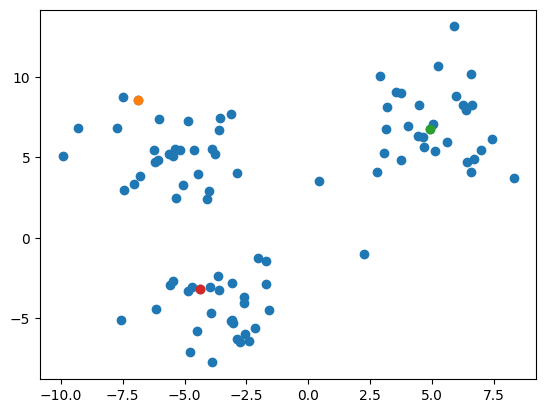

['green', 'purple', 'brown']


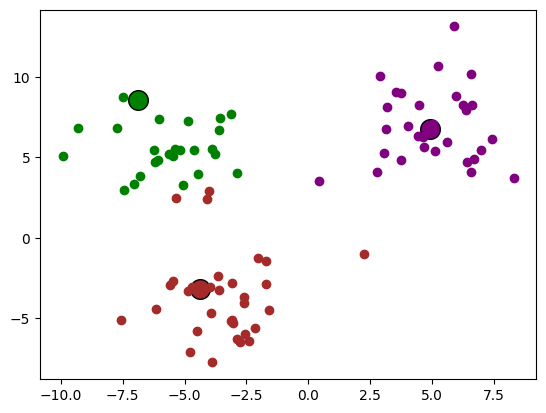

In [ ]:
X,y=generate_sample(90,2,2)
center_idx,centers = choice_random_center(90,3,X)
flag=True
while flag:
    res = check_centers(centers,10)
    if res:
        flag=False
        print("centers find")
    else:
        center_idx,centers = choice_random_center(90,3,X)


plt.scatter(X[:,0],X[:,1])
for c in centers:
    plt.scatter(c[0],c[1]) 
plt.show() 

matrix,clusters=create_distance_matrix(X,centers)
#clusters
colors = generate_random_color(3)
print(colors)
# plt.scatter(X[:,0],X[:,1])
for idx , c in enumerate(centers):
    plt.scatter(c[0],c[1],color=colors[idx],s=200,edgecolors="black") 
    z = X[clusters==idx]
    plt.scatter(z[:,0],z[:,1],color=colors[idx])
plt.show() 


